In [2]:
import pandas as pd
import scanpy as sc
import numpy as np
import os
import anndata
from matplotlib.pyplot import rc_context
sc.set_figure_params(dpi=100)

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white')

scanpy==1.9.6 anndata==0.10.3 umap==0.5.4 numpy==1.23.4 scipy==1.11.3 pandas==2.1.1 scikit-learn==1.3.2 statsmodels==0.14.0 igraph==0.10.8 pynndescent==0.5.10


In [4]:
os.chdir('/exports/archive/hg-exon-skip/alireza/expression_matrices/WMB-10Xv2/20230630/')

In [4]:
os.getcwd()

'/exports/archive/hg-exon-skip/alireza/expression_matrices/WMB-10Xv2/20230630'

In [8]:
def pp(h5_path):
    adata = sc.read_h5ad(h5_path)
    gene_symbols = adata.var['gene_symbol'].tolist()
    adata.var_names = gene_symbols
    adata.var_names_make_unique()
    sc.pp.filter_cells(adata, min_genes=200) #get rid of cells with fewer than 200 genes
    sc.pp.filter_genes(adata, min_cells=3) #get rid of genes that are found in fewer than 3 cells
    adata.var['mt'] = adata.var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
    upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, .98)
    lower_lim = np.quantile(adata.obs.n_genes_by_counts.values, .02)
    adata = adata[(adata.obs.n_genes_by_counts < upper_lim) & (adata.obs.n_genes_by_counts > lower_lim)]
    adata = adata[adata.obs.pct_counts_mt < 20]
    sc.pp.normalize_total(adata, target_sum=1e4) #normalize every cell to 10,000 UMI
    sc.pp.log1p(adata) #change to log counts
    sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5) #these are default values
    adata.raw = adata #save raw data before processing values and further filtering
    adata = adata[:, adata.var.highly_variable] #filter highly variable
    sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt']) #Regress out effects of total counts per cell and the percentage of mitochondrial genes expressed
    sc.pp.scale(adata, max_value=10) #scale each gene to unit variance
    sc.tl.pca(adata, svd_solver='arpack')
    sc.pp.neighbors(adata, n_neighbors=10, n_pcs=20)
    sc.tl.leiden(adata, resolution = 0.25)
    sc.tl.umap(adata)
    adata.write('adata.h5ad')
    return adata

In [5]:
ls

adata.h5ad  Untitled.ipynb                   WMB-10Xv2-Isocortex-3-log2.h5ad
ctxsp.h5ad  WMB-10Xv2-CTXsp-log2.h5ad        WMB-10Xv2-Isocortex-3-raw.h5ad
hpf.h5ad    WMB-10Xv2-CTXsp-raw.h5ad         WMB-10Xv2-Isocortex-4-log2.h5ad
hy.h5ad     WMB-10Xv2-HPF-log2.h5ad          WMB-10Xv2-Isocortex-4-raw.h5ad
iso1.h5ad   WMB-10Xv2-HPF-raw.h5ad           WMB-10Xv2-MB-log2.h5ad
iso2.h5ad   WMB-10Xv2-HY-log2.h5ad           WMB-10Xv2-MB-raw.h5ad
iso3.h5ad   WMB-10Xv2-HY-raw.h5ad            WMB-10Xv2-OLF-log2.h5ad
iso4.h5ad   WMB-10Xv2-Isocortex-1-log2.h5ad  WMB-10Xv2-OLF-raw.h5ad
mb.h5ad     WMB-10Xv2-Isocortex-1-raw.h5ad   WMB-10Xv2-TH-log2.h5ad
olf.h5ad    WMB-10Xv2-Isocortex-2-log2.h5ad  WMB-10Xv2-TH-raw.h5ad
th.h5ad     WMB-10Xv2-Isocortex-2-raw.h5ad


In [5]:
ctxsp = pp('WMB-10Xv2-CTXsp-raw.h5ad')

NameError: name 'pp' is not defined

In [ ]:
hpf = pp('WMB-10Xv2-HPF-raw.h5ad')
hy = pp('WMB-10Xv2-HY-raw.h5ad')
iso1 = pp('WMB-10Xv2-Isocortex-1-raw.h5ad')
iso2 = pp('WMB-10Xv2-Isocortex-2-raw.h5ad')
iso3 = pp('WMB-10Xv2-Isocortex-3-raw.h5ad')
iso4 = pp('WMB-10Xv2-Isocortex-4-raw.h5ad')
mb = pp('WMB-10Xv2-MB-raw.h5ad')
olf = pp('WMB-10Xv2-OLF-raw.h5ad')
th = pp('WMB-10Xv2-TH-raw.h5ad')

In [7]:
hy = sc.read_h5ad('hy.h5ad')

In [8]:
iso1 = sc.read_h5ad('iso1.h5ad')

In [ ]:
iso2 = sc.read_h5ad('iso2.h5ad')

In [ ]:
iso3 = sc.read_h5ad('iso3.h5ad')

In [ ]:
iso4 = sc.read_h5ad('iso4.h5ad')

In [ ]:
mb = sc.read_h5ad('mb.h5ad')

In [ ]:
olf = sc.read_h5ad('olf.h5ad')

In [ ]:
th = sc.read_h5ad('th.h5ad')

In [6]:
ctxsp =sc.read_h5ad('ctxsp.h5ad')
ctxsp

AnnData object with n_obs × n_vars = 42530 × 2322
    obs: 'cell_barcode', 'library_label', 'anatomical_division_label', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden'
    var: 'gene_symbol', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors', 'normalization', 'parent', 'parent_layer', 'parent_rows', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [8]:
hpf = sc.read_h5ad('hpf.h5ad')
hpf

AnnData object with n_obs × n_vars = 199925 × 2014
    obs: 'cell_barcode', 'library_label', 'anatomical_division_label', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden'
    var: 'gene_symbol', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors', 'normalization', 'parent', 'parent_layer', 'parent_rows', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


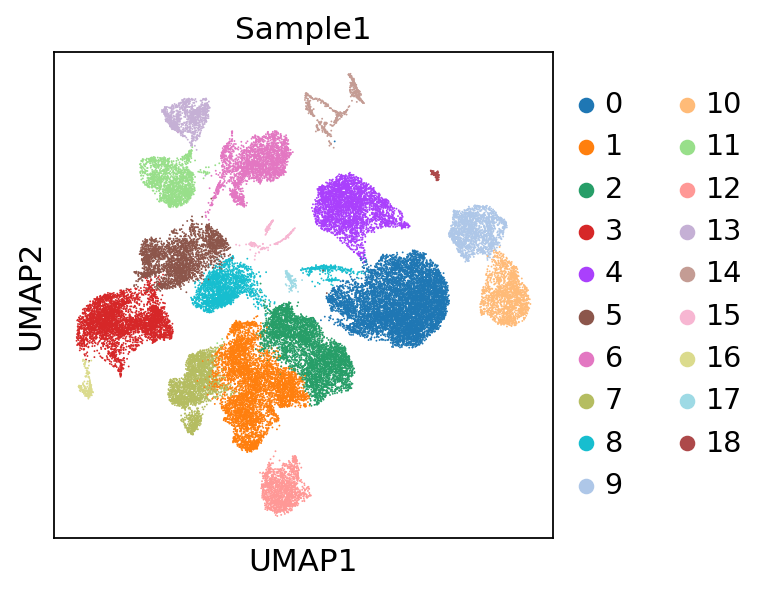

In [10]:
with rc_context({'figure.figsize': (4, 4)}):
    sc.pl.umap(ctxsp, color = 'leiden',title = 'Sample1')

/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


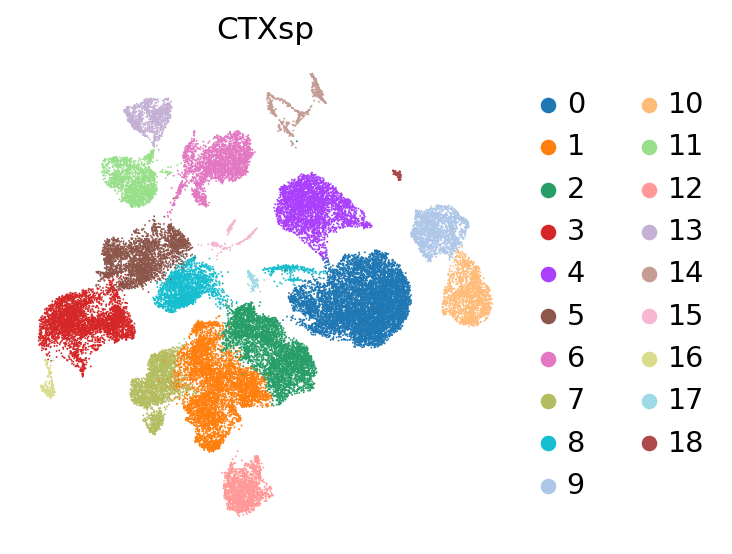

/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


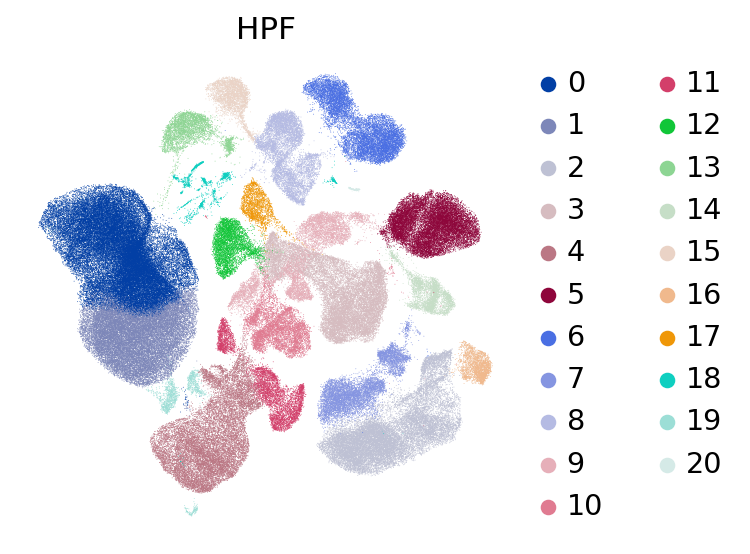

In [11]:
with rc_context({'figure.figsize': (4, 4)}):
    sc.pl.umap(ctxsp, color = 'leiden', frameon = False, title = 'CTXsp')
    sc.pl.umap(hpf, color = 'leiden', frameon = False, title = 'HPF')

In [12]:
ctxsp.obs['region'] = 'CTXsp'
hpf.obs['region'] = 'HPF'

#lung3.obs['Sample'] = 'lung3' #if more than 2 samples

In [13]:
hy.obs['region'] = 'hy'
iso1.obs['region'] = 'iso1'
iso2.obs['region'] = 'iso2'
iso3.obs['region'] = 'iso3'
iso4.obs['region'] = 'iso4'
mb.obs['region'] = 'mb'
olf.obs['region'] = 'olf'
th.obs['region'] = 'th'

In [14]:
var_names = hpf.var_names.intersection(ctxsp.var_names)
var_names = var_names.intersection(hy.var_names) #if more than 2 samples
var_names = var_names.intersection(iso1.var_names)
var_names = var_names.intersection(iso2.var_names)
var_names = var_names.intersection(iso3.var_names)
var_names = var_names.intersection(iso4.var_names)
var_names = var_names.intersection(mb.var_names)
var_names = var_names.intersection(olf.var_names)
var_names = var_names.intersection(th.var_names)
#lung3 = lung3[:, var_names] #if more than 2 samples

In [1]:
hpf = hpf[:, var_names]
ctxsp = ctxsp[:, var_names]
hy = hy[:, var_names]
iso1 = iso1[:, var_names]
iso2 = iso2[: , var_names]
iso3 = iso3[: , var_names]
iso4 = iso4[: , var_names]
mb   = mb[: , var_names]
olf = olf[: , var_names]
th = th[: , var_names]

NameError: name 'hpf' is not defined

In [14]:
sc.tl.ingest(ctxsp, hpf, obs= 'leiden')
sc.tl.ingest(hy, hpf, obs= 'leiden')#if more than 2 samples
sc.tl.ingest(iso1, hpf, obs= 'leiden')
sc.tl.ingest(iso2, hpf, obs= 'leiden')
sc.tl.ingest(iso3, hpf, obs= 'leiden')
sc.tl.ingest(iso4, hpf, obs= 'leiden')
sc.tl.ingest(mb, hpf, obs= 'leiden')
sc.tl.ingest(olf, hpf, obs= 'leiden')
sc.tl.ingest(th, hpf, obs= 'leiden')

/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/tools/_ingest.py:511: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  values = [cat_array[inds].mode()[0] for inds in self._indices]
<frozen _collections_abc>:949: ImplicitModificationWarning: Setting element `.obsm['rep']` of view, initializing view as actual.
<frozen _collections_abc>:949: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
<frozen _collect

/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


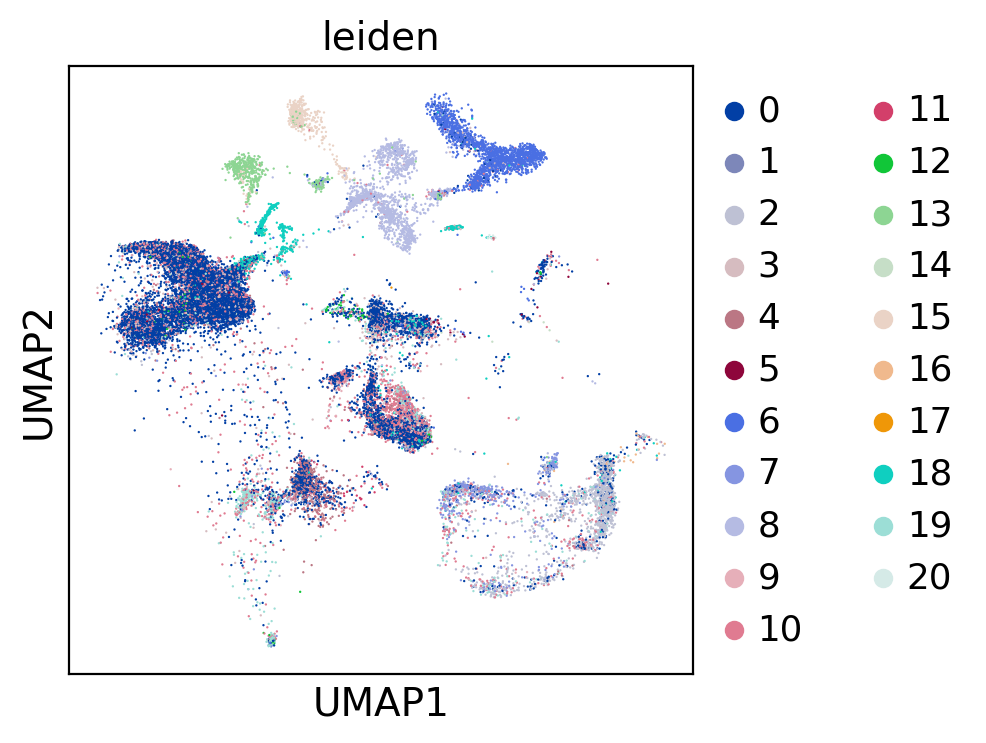

/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/anndata/_core/anndata.py:1292: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


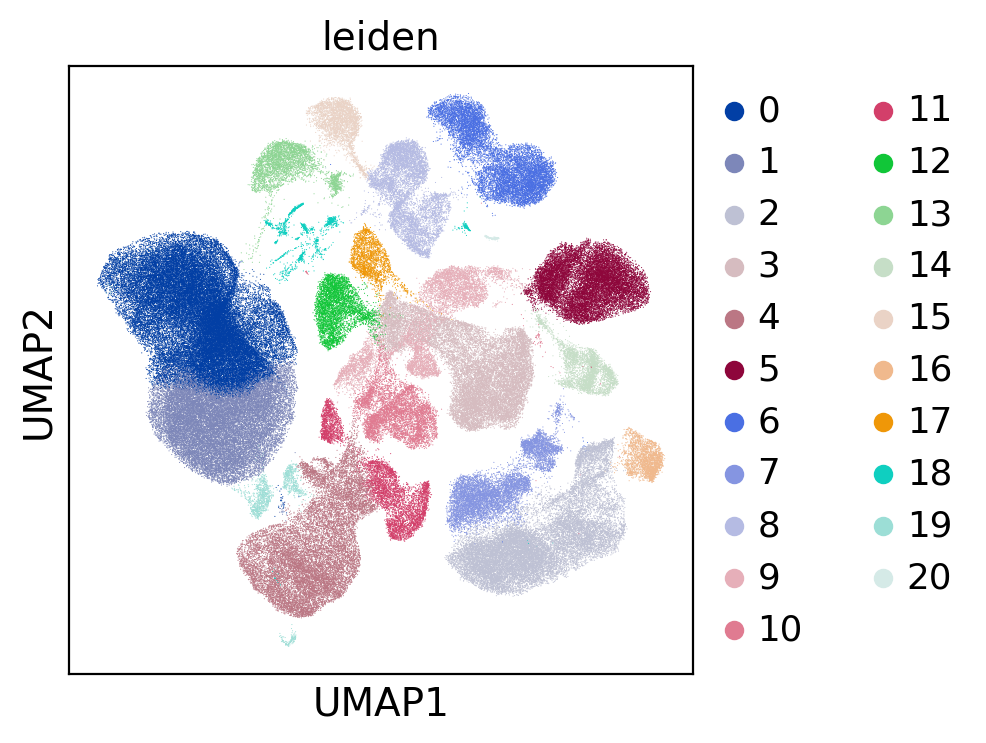

In [15]:
with rc_context({'figure.figsize': (4, 4)}):
    sc.pl.umap(ctxsp, color = 'leiden', save='ctxsp.png')
    sc.pl.umap(hpf, color = 'leiden'.save)

In [16]:
merged = hpf.concatenate(ctxsp)
merged = merged.concatenate(hy) #if more than 2 samples
merged = merged.concatenate(iso1)
merged = merged.concatenate(iso2)
merged = merged.concatenate(iso3)
merged = merged.concatenate(iso4)
merged = merged.concatenate(mb)
merged = merged.concatenate(olf)
merged = merged.concatenate(th)

/tmp/ipykernel_4058620/1905726584.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = hpf.concatenate(ctxsp)


In [6]:
merged

NameError: name 'merged' is not defined

In [1]:
with rc_context({'figure.figsize': (4, 4)}):
    sc.pl.umap(merged, color = 'leiden', frameon = False, title = 'Integrated', save='merged_leiden.png')
    sc.pl.umap(merged, color = 'region', save='merged_region.png')

NameError: name 'rc_context' is not defined

In [20]:
counts = merged.obs.groupby(['region', 'leiden']).count().reset_index()

def map_per(x):
    samp, y = x
    tot = counts[counts.region == samp].total_counts.sum()
    return (y/tot)*100

counts['per'] = counts[['region', 'total_counts']].apply(map_per, axis = 1)

counts

/tmp/ipykernel_4058620/2206726850.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = merged.obs.groupby(['region', 'leiden']).count().reset_index()


,region,leiden,cell_barcode,library_label,anatomical_division_label,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,batch,per
0,CTXsp,0,20848,20848,20848,20848,20848,20848,20848,20848,20848,49.019516
1,CTXsp,1,0,0,0,0,0,0,0,0,0,0.000000
2,CTXsp,2,1992,1992,1992,1992,1992,1992,1992,1992,1992,4.683753
3,CTXsp,3,1951,1951,1951,1951,1951,1951,1951,1951,1951,4.587350
4,CTXsp,4,1231,1231,1231,1231,1231,1231,1231,1231,1231,2.894427
5,CTXsp,5,128,128,128,128,128,128,128,128,128,0.300964
6,CTXsp,6,1969,1969,1969,1969,1969,1969,1969,1969,1969,4.629673
7,CTXsp,7,763,763,763,763,763,763,763,763,763,1.794028
8,CTXsp,8,1775,1775,1775,1775,1775,1775,1775,1775,1775,4.173525
9,CTXsp,9,493,493,493,493,493,493,493,493,493,1.159182


/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/exports/archive/hg-exon-skip/alireza/conda/envs/scanpy/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


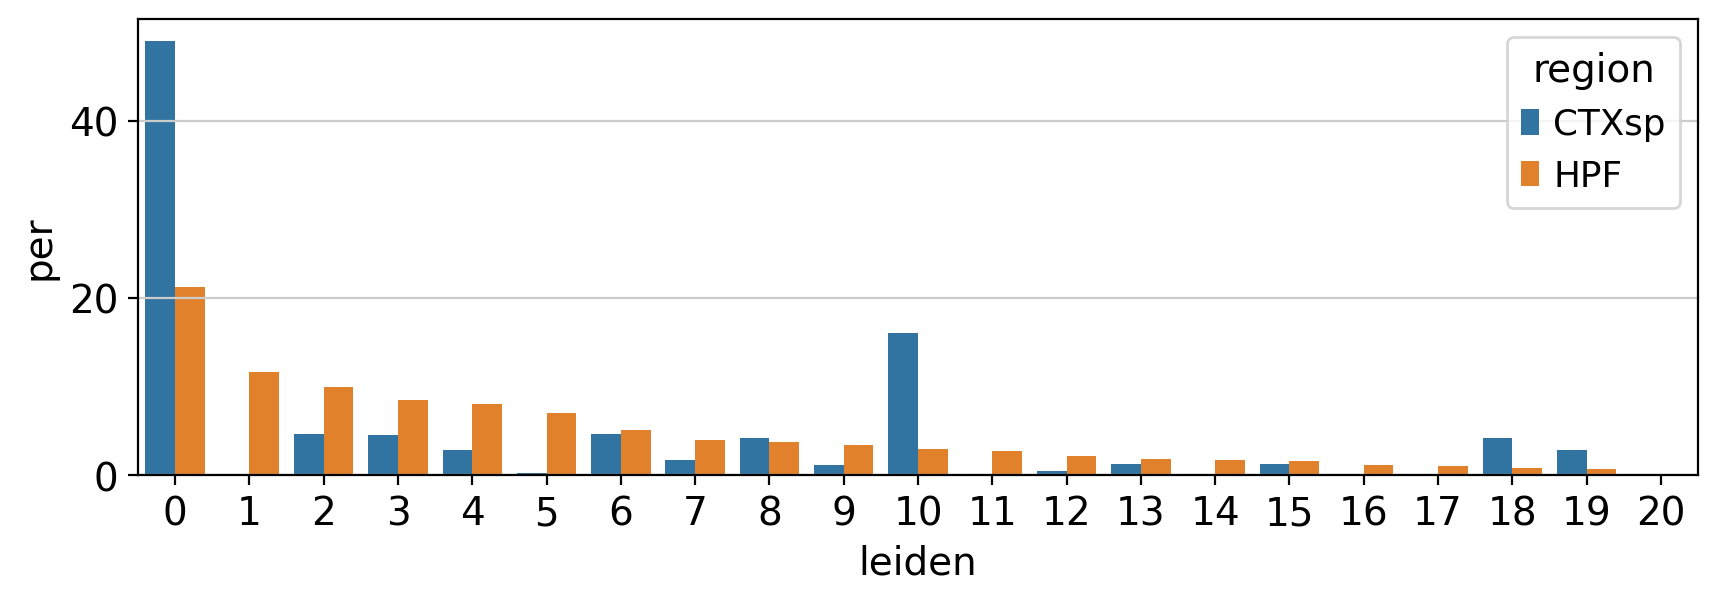

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (10,3))
ax = sns.barplot(x = 'leiden', y = 'per', hue = 'region', data = counts)